In [14]:
def calcola_spettro(data):
    # Calcola la trasformata di Fourier dell'array registrato
    spettro_frequenze = np.fft.rfft(data)
    frequenze = np.fft.rfftfreq(len(data), 1 / 48000)
    return spettro_frequenze, frequenze

In [27]:
import numpy as np
import soundcard as sc

# Elenco e stampa dei dispositivi disponibili
speakers = sc.all_speakers()
print(f"Speaker disponibili: {speakers}\n")

default_speaker = sc.default_speaker()
print(f"Speaker selezionato: {default_speaker}\n")

mics = sc.all_microphones()
print(f"Microfoni disponibili: {mics}\n")

default_mic = sc.default_microphone()
print(f"Microfono selezionato: {default_mic}\n")

# Acquisizione di 1 secondo di audio (48000 frame a 48kHz)
samplerate = 48000
numframes = 480000
print("Registrazione in corso...")
data = default_mic.record(samplerate=samplerate, numframes=numframes)
print("Array acquisito:")
print(data)
print(f"\nL'array dei dati registrati è lungo {len(data)}\n")

# Riproduzione sicura dei dati
max_val = np.max(np.abs(data))
if max_val > 0:
  normalized_data = data / max_val
  print("Riproduzione in corso...")
  default_speaker.play(normalized_data, samplerate=samplerate)
else:
  print(
      "L'audio registrato è completamente silenzioso (nessun picco rilevato)."
  )

Speaker disponibili: [<Speaker Speaker (Realtek(R) Audio) (2 channels)>]

Speaker selezionato: <Speaker Speaker (Realtek(R) Audio) (2 channels)>

Microfoni disponibili: [<Microphone Gruppo microfoni (Tecnologia Intel® Smart Sound per microfoni digitali) (2 channels)>]

Microfono selezionato: <Microphone Gruppo microfoni (Tecnologia Intel® Smart Sound per microfoni digitali) (2 channels)>

Registrazione in corso...
Array acquisito:
[[ 0.0000000e+00  2.0000000e-10]
 [ 0.0000000e+00 -3.0000000e-10]
 [ 1.0000000e-10  1.0000000e-10]
 ...
 [ 4.7689995e-05  4.7686339e-05]
 [ 4.2615779e-05  4.2610343e-05]
 [ 2.1622376e-05  2.1620397e-05]]

L'array dei dati registrati è lungo 480000

Riproduzione in corso...


In [38]:
data.shape

(480000, 2)

In [67]:

default_speaker.play(data, samplerate=samplerate*2)


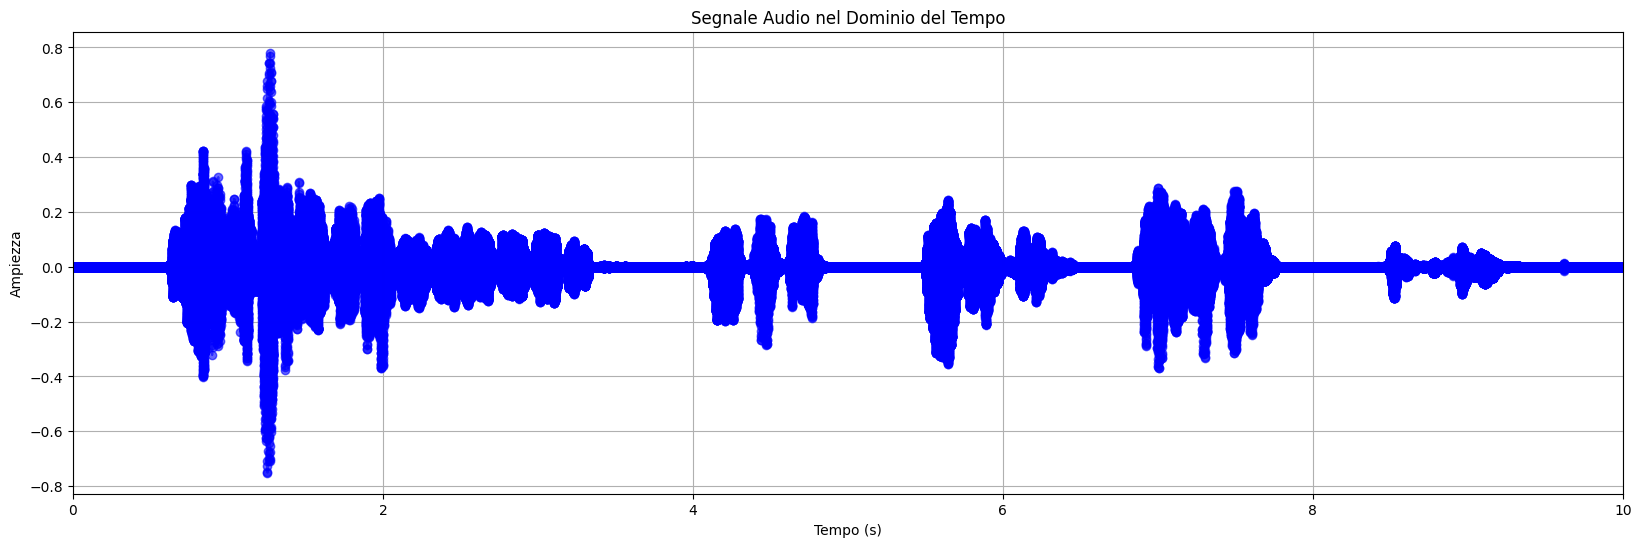

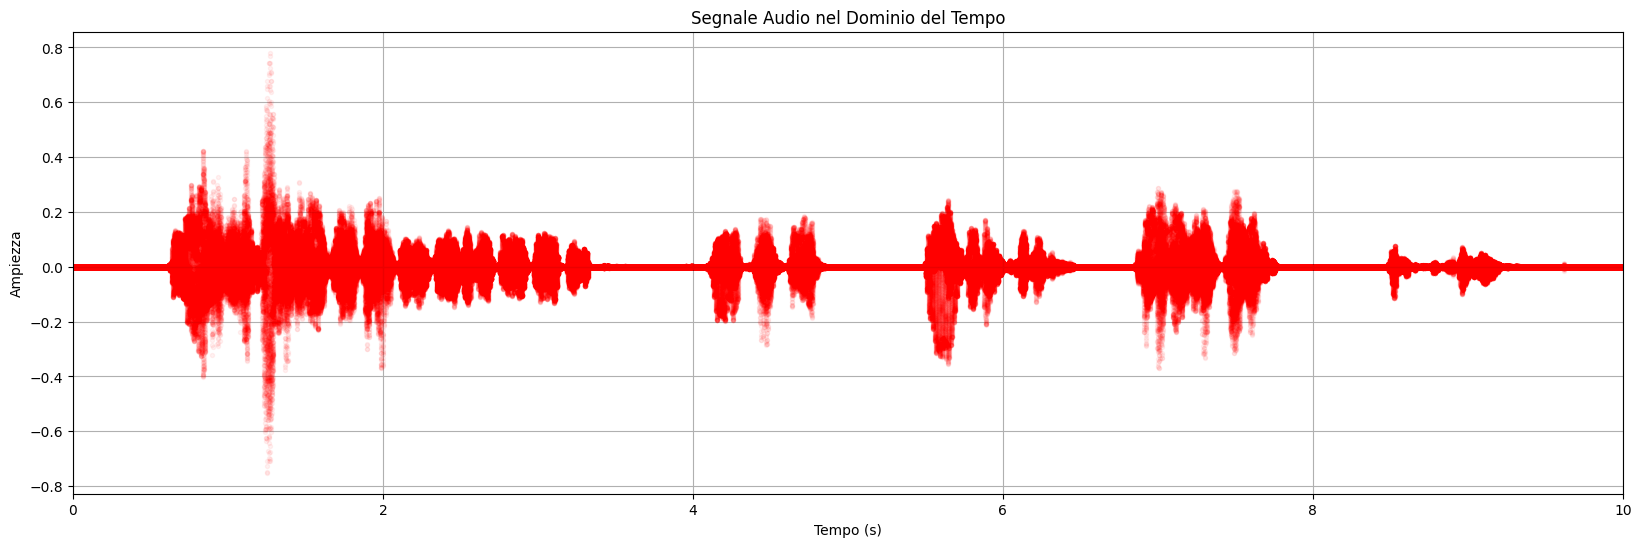

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Assumendo che 'data' sia già stato acquisito e 'samplerate = 48000'
# Se il microfono è stereo (es. shape (48000, 2)), prendiamo ad esempio solo il primo canale:
if data.ndim > 1:
  audio_signal = data[:,0]
  ciccio=data[:, 1]
else:
  audio_signal = data

duration = len(audio_signal) / samplerate
time_axis = np.linspace(0, duration, len(audio_signal))

plt.figure(figsize=(20, 6))
plt.plot(time_axis, audio_signal, color='b', alpha=0.6)
plt.title('Segnale Audio nel Dominio del Tempo')
plt.xlabel('Tempo (s)')
plt.ylabel('Ampiezza')
plt.grid(True)
plt.xlim(0, 10)
plt.show()

plt.figure(figsize=(20, 6))
plt.errorbar(time_axis, ciccio, color='r', fmt='.', alpha=0.05)
plt.title('Segnale Audio nel Dominio del Tempo')
plt.xlabel('Tempo (s)')
plt.ylabel('Ampiezza')
plt.grid(True)
plt.xlim(0, 10)
plt.show()

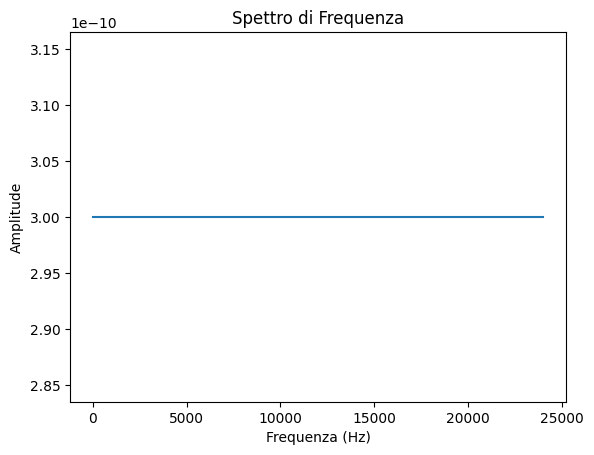

In [20]:
import matplotlib.pyplot as plt
spettro_frequenze, frequenze = calcola_spettro(data[1])
plt.plot(frequenze, np.abs(spettro_frequenze))
plt.xlabel("Frequenza (Hz)")
plt.ylabel("Amplitude")
plt.title("Spettro di Frequenza")
plt.show()